# CrisisLens data EDA

This notebook studies the data for CrisisLens. CrisisLens helps users sort new disaster messages into clear information boards.

It checks:

- HumAID-all and its event files;
- the small CrisisMMD annotation files (the 1.8 GB image archive is not downloaded);
- labels, events, splits, text length and duplicates;
- a test plan for a disaster that was not used for training.

Run the notebook from the project folder. Missing files are downloaded into `data/raw/`. Tables and figures are saved in `outputs/eda/`.

## What this cell does

It sets the project paths and imports the packages used below. The paths are kept here so the notebook is easy to run on another machine.

In [1]:
from __future__ import annotations

import json
import re
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

def find_project_root() -> Path:
    candidates = [Path.cwd(), Path(__file__).resolve().parent] if "__file__" in globals() else [Path.cwd()]
    candidates += list(Path.cwd().parents)
    for candidate in candidates:
        if (candidate / "notebooks").exists() and (candidate / "outputs").exists():
            return candidate
    return Path.cwd()

PROJECT_ROOT = find_project_root()
RAW = PROJECT_ROOT / "data" / "raw"
HUMAID_RAW = RAW / "humaid"
EVENTS_RAW = RAW / "humaid_events"
CRISISMMD_RAW = RAW / "crisismmd"
EDA_OUT = PROJECT_ROOT / "outputs" / "eda"
FIG_OUT = EDA_OUT / "figures"
for folder in [HUMAID_RAW, EVENTS_RAW, CRISISMMD_RAW, EDA_OUT, FIG_OUT]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"EDA output:   {EDA_OUT}")

Project root: C:\Users\Kunal Mistry\Documents\MDSI\NLP\Assignment_3\36118-ANLP-AT2
EDA output:   C:\Users\Kunal Mistry\Documents\MDSI\NLP\Assignment_3\36118-ANLP-AT2\outputs\eda


## What this cell does

It downloads the files needed for this EDA. HumAID-all gives the main splits. HumAID-events adds event names for the new-event test. CrisisMMD gives its labels and splits. The image archive is not needed here.

In [2]:
def download(url: str, destination: Path) -> None:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        return
    print(f"Downloading {destination.name} ...")
    urllib.request.urlretrieve(url, destination)

def download_humaid_all() -> None:
    base = "https://huggingface.co/datasets/QCRI/HumAID-all/resolve/main/data/"
    for filename in [
        "train-00000-of-00001.parquet",
        "validation-00000-of-00001.parquet",
        "test-00000-of-00001.parquet",
    ]:
        download(base + filename, HUMAID_RAW / filename)

def download_humaid_events() -> None:
    api_url = "https://huggingface.co/api/datasets/QCRI/HumAID-events/tree/main?recursive=true"
    entries = json.loads(urllib.request.urlopen(api_url, timeout=60).read().decode("utf-8"))
    event_files = [
        item["path"] for item in entries
        if item.get("type") == "file" and item["path"].endswith(".json")
    ]
    for remote_path in event_files:
        local_name = remote_path.replace("/", "__")
        url = "https://huggingface.co/datasets/QCRI/HumAID-events/resolve/main/" + remote_path
        download(url, EVENTS_RAW / local_name)

def download_crisismmd_annotations() -> None:
    archive = CRISISMMD_RAW / "crisismmd_datasplit_all.zip"
    download(
        "https://crisisnlp.qcri.org/data/crisismmd/crisismmd_datasplit_all.zip",
        archive,
    )
    marker = CRISISMMD_RAW / "annotations" / "crisismmd_datasplit_all" / "task_humanitarian_text_img_train.tsv"
    if not marker.exists():
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(CRISISMMD_RAW / "annotations")

download_humaid_all()
download_humaid_events()
download_crisismmd_annotations()
print("Downloads are ready.")

Downloads are ready.


## What this cell does

It loads the three HumAID splits and checks them against the event files. The event files are used for event analysis because the combined Parquet files have no event column.

In [3]:
split_file_map = {
    "train": HUMAID_RAW / "train-00000-of-00001.parquet",
    "validation": HUMAID_RAW / "validation-00000-of-00001.parquet",
    "test": HUMAID_RAW / "test-00000-of-00001.parquet",
}

humaids = []
for split, path in split_file_map.items():
    frame = pd.read_parquet(path)
    frame["split"] = split
    humaids.append(frame)
humaid_all = pd.concat(humaids, ignore_index=True)

event_frames = []
for path in sorted(EVENTS_RAW.glob("*.json")):
    name = path.name
    event, split_file = name.rsplit("__", 1)
    split = split_file.removesuffix(".json")
    frame = pd.read_json(path)
    frame["event"] = event
    frame["split"] = {"dev": "validation"}.get(split, split)
    event_frames.append(frame)
humaid_events = pd.concat(event_frames, ignore_index=True)

def event_type(event: str) -> str:
    if "hurricane" in event:
        return "hurricane"
    if "earthquake" in event:
        return "earthquake"
    if "flood" in event:
        return "flood"
    if "wildfire" in event:
        return "wildfire"
    return "other"

humaid_events["event_type"] = humaid_events["event"].map(event_type)
humaid_events["text"] = humaid_events["tweet_text"].fillna("").astype(str)

print("Combined HumAID files:", humaid_all.shape)
print("Event-wise HumAID files:", humaid_events.shape)
print("Combined labels:", sorted(humaid_all["class_label"].unique()))
print("Event-wise events:", humaid_events["event"].nunique())

count_check = (
    humaid_all.groupby(["split", "class_label"]).size().rename("combined_rows")
    .to_frame()
    .join(
        humaid_events.groupby(["split", "class_label"]).size().rename("eventwise_rows"),
        how="outer",
    )
    .fillna(0)
    .astype(int)
)
count_check["difference"] = count_check["combined_rows"] - count_check["eventwise_rows"]
display(count_check.reset_index())
count_check.reset_index().to_csv(EDA_OUT / "humaid_loader_count_check.csv", index=False)

Combined HumAID files: (76484, 3)
Event-wise HumAID files: (76484, 7)
Combined labels: ['caution_and_advice', 'displaced_people_and_evacuations', 'infrastructure_and_utility_damage', 'injured_or_dead_people', 'missing_or_found_people', 'not_humanitarian', 'other_relevant_information', 'requests_or_urgent_needs', 'rescue_volunteering_or_donation_effort', 'sympathy_and_support']
Event-wise events: 19


,split,class_label,combined_rows,eventwise_rows,difference
0,test,caution_and_advice,1070,1070,0
1,test,displaced_people_and_evacuations,790,790,0
2,test,infrastructure_and_utility_damage,1617,1617,0
3,test,injured_or_dead_people,1447,1447,0
4,test,missing_or_found_people,72,72,0
5,test,not_humanitarian,1245,1245,0
6,test,other_relevant_information,2407,2407,0
7,test,requests_or_urgent_needs,521,521,0
8,test,rescue_volunteering_or_donation_effort,4219,4219,0
9,test,sympathy_and_support,1772,1772,0


## HumAID dataset overview

These tables show the sample sizes, labels and event types used by later model work. The files contain ten labels. The dataset card lists an older eleven-label set, so we record the difference here.

In [4]:
split_summary = (
    humaid_events.groupby("split")
    .size()
    .rename("rows")
    .to_frame()
    .assign(share=lambda x: x["rows"] / x["rows"].sum())
    .reset_index()
)
label_summary = (
    humaid_events.groupby(["split", "class_label"])
    .size()
    .rename("rows")
    .reset_index()
)
label_summary["split_share"] = label_summary["rows"] / label_summary.groupby("split")["rows"].transform("sum")
label_summary["overall_share"] = label_summary["rows"] / len(humaid_events)
event_summary = (
    humaid_events.groupby(["event", "event_type", "split"])
    .size()
    .rename("rows")
    .reset_index()
)
event_label_counts = (
    humaid_events.groupby(["event", "event_type", "class_label"])
    .size()
    .rename("rows")
    .reset_index()
)
event_label_counts["event_share"] = event_label_counts["rows"] / event_label_counts.groupby("event")["rows"].transform("sum")
event_type_summary = humaid_events.groupby("event_type").size().rename("rows").reset_index()

for frame, filename in [
    (split_summary, "humaid_split_summary.csv"),
    (label_summary, "humaid_label_distribution.csv"),
    (event_summary, "humaid_event_distribution.csv"),
    (event_label_counts, "humaid_event_label_counts.csv"),
    (event_type_summary, "humaid_event_type_distribution.csv"),
]:
    frame.to_csv(EDA_OUT / filename, index=False)

display(split_summary)
display(label_summary.sort_values(["split", "rows"], ascending=[True, False]))
display(event_summary.pivot_table(index="event", columns="split", values="rows", fill_value=0))

,split,rows,share
0,test,15160,0.198211
1,train,53531,0.699898
2,validation,7793,0.101891


,split,class_label,rows,split_share,overall_share
8,test,rescue_volunteering_or_donation_effort,4219,0.278298,0.055162
6,test,other_relevant_information,2407,0.158773,0.031471
9,test,sympathy_and_support,1772,0.116887,0.023168
2,test,infrastructure_and_utility_damage,1617,0.106662,0.021142
3,test,injured_or_dead_people,1447,0.095449,0.018919
5,test,not_humanitarian,1245,0.082124,0.016278
0,test,caution_and_advice,1070,0.070580,0.013990
1,test,displaced_people_and_evacuations,790,0.052111,0.010329
7,test,requests_or_urgent_needs,521,0.034367,0.006812
4,test,missing_or_found_people,72,0.004749,0.000941


split,test,train,validation
event,,,
california_wildfires_2018,1461.0,5163.0,752.0
canada_wildfires_2016,445.0,1569.0,228.0
cyclone_idai_2019,779.0,2753.0,401.0
ecuador_earthquake_2016,310.0,1094.0,159.0
greece_wildfires_2018,301.0,1060.0,154.0
hurricane_dorian_2019,1508.0,5329.0,776.0
hurricane_florence_2018,1241.0,4384.0,639.0
hurricane_harvey_2017,1805.0,6378.0,929.0
hurricane_irma_2017,1862.0,6579.0,958.0


## What this cell does

These figures show class imbalance and event coverage. We show counts as well as proportions because a high rate in a small event may not be reliable.

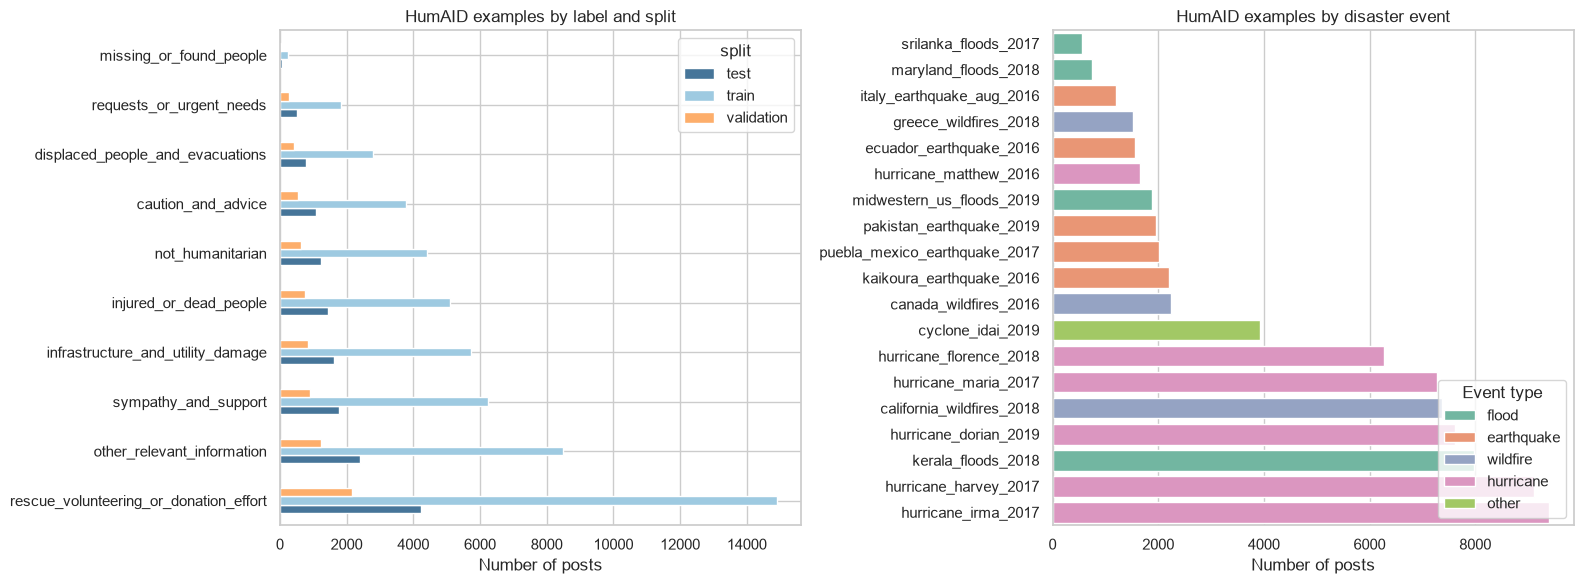

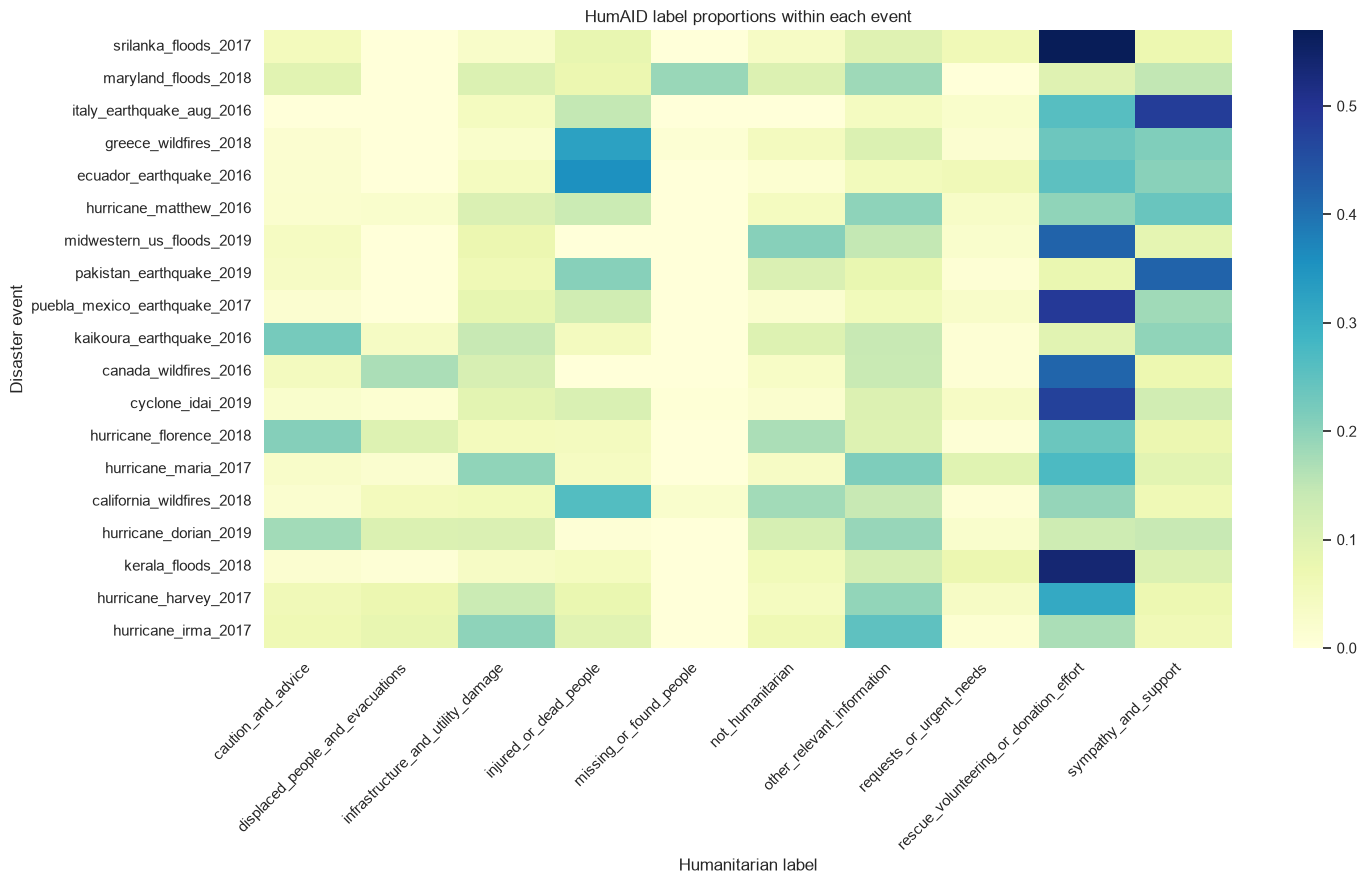

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
label_plot = label_summary.pivot(index="class_label", columns="split", values="rows").fillna(0)
label_plot = label_plot.loc[label_plot.sum(axis=1).sort_values(ascending=False).index]
label_plot.plot.barh(ax=axes[0], color=["#467599", "#9ecae1", "#fdae6b"])
axes[0].set_title("HumAID examples by label and split")
axes[0].set_xlabel("Number of posts")
axes[0].set_ylabel("")

event_plot = event_summary.groupby(["event", "event_type"], as_index=False)["rows"].sum().sort_values("rows")
sns.barplot(data=event_plot, x="rows", y="event", hue="event_type", dodge=False, ax=axes[1], palette="Set2")
axes[1].set_title("HumAID examples by disaster event")
axes[1].set_xlabel("Number of posts")
axes[1].set_ylabel("")
axes[1].legend(title="Event type", loc="lower right")
plt.tight_layout()
fig.savefig(FIG_OUT / "humaid_label_and_event_counts.png", dpi=180, bbox_inches="tight")
plt.show()

heat = event_label_counts.pivot(index="event", columns="class_label", values="event_share").fillna(0)
heat = heat.loc[event_plot["event"].tolist()]
plt.figure(figsize=(15, 9))
sns.heatmap(heat, cmap="YlGnBu", annot=False)
plt.title("HumAID label proportions within each event")
plt.xlabel("Humanitarian label")
plt.ylabel("Disaster event")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_OUT / "humaid_event_label_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

## Text quality and leakage checks

This cell checks text length, links, mentions, hashtags and retweets. It also checks exact and simple normalised duplicates across splits. Repeated posts, URLs or event names can make a model look better than it is.

In [6]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", re.I)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#\w+")

def normalise_for_duplicate(text: str) -> str:
    text = URL_RE.sub(" <URL> ", text.lower())
    text = MENTION_RE.sub(" <USER> ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

humaid_events["word_count"] = humaid_events["text"].str.findall(r"\b\w+\b").str.len()
humaid_events["char_count"] = humaid_events["text"].str.len()
humaid_events["has_url"] = humaid_events["text"].str.contains(URL_RE)
humaid_events["has_mention"] = humaid_events["text"].str.contains(MENTION_RE)
humaid_events["has_hashtag"] = humaid_events["text"].str.contains(HASHTAG_RE)
humaid_events["is_retweet"] = humaid_events["text"].str.match(r"^\s*RT\b", case=False)
humaid_events["normalised_text"] = humaid_events["text"].map(normalise_for_duplicate)

text_stats = (
    humaid_events.groupby(["split", "event_type", "class_label"])
    .agg(
        rows=("text", "size"),
        words_median=("word_count", "median"),
        words_mean=("word_count", "mean"),
        words_p90=("word_count", lambda x: x.quantile(0.90)),
        chars_median=("char_count", "median"),
        url_rate=("has_url", "mean"),
        mention_rate=("has_mention", "mean"),
        hashtag_rate=("has_hashtag", "mean"),
        retweet_rate=("is_retweet", "mean"),
    )
    .reset_index()
)
exact_duplicate_count = int(humaid_events["text"].duplicated(keep=False).sum())
normalised_duplicate_count = int(humaid_events["normalised_text"].duplicated(keep=False).sum())
cross_split_norm = humaid_events.groupby("normalised_text")["split"].nunique()
cross_split_duplicate_groups = int((cross_split_norm > 1).sum())
duplicate_summary = pd.DataFrame(
    {
        "check": [
            "exact duplicate rows",
            "normalised duplicate rows",
            "normalised duplicate groups crossing splits",
        ],
        "value": [exact_duplicate_count, normalised_duplicate_count, cross_split_duplicate_groups],
    }
)
text_stats.to_csv(EDA_OUT / "humaid_text_statistics.csv", index=False)
duplicate_summary.to_csv(EDA_OUT / "humaid_duplicate_summary.csv", index=False)

display(text_stats.head(20))
display(duplicate_summary)

,split,event_type,class_label,rows,words_median,words_mean,words_p90,chars_median,url_rate,mention_rate,hashtag_rate,retweet_rate
0,test,earthquake,caution_and_advice,125,16.0,16.392000,24.0,109.0,0.0,0.464000,0.672000,0.376000
1,test,earthquake,displaced_people_and_evacuations,17,18.0,17.352941,22.0,115.0,0.0,0.529412,0.764706,0.411765
2,test,earthquake,infrastructure_and_utility_damage,145,17.0,17.241379,26.0,110.0,0.0,0.489655,0.731034,0.413793
3,test,earthquake,injured_or_dead_people,294,17.0,18.193878,26.0,110.0,0.0,0.503401,0.557823,0.421769
4,test,earthquake,not_humanitarian,98,21.0,23.142857,42.0,122.0,0.0,0.336735,0.765306,0.112245
5,test,earthquake,other_relevant_information,141,18.0,19.425532,33.0,113.0,0.0,0.460993,0.645390,0.340426
6,test,earthquake,requests_or_urgent_needs,45,18.0,17.200000,24.6,115.0,0.0,0.600000,0.533333,0.288889
7,test,earthquake,rescue_volunteering_or_donation_effort,408,17.0,17.693627,24.0,115.5,0.0,0.598039,0.610294,0.392157
8,test,earthquake,sympathy_and_support,500,19.0,19.358000,27.0,119.5,0.0,0.458000,0.772000,0.394000
9,test,flood,caution_and_advice,63,28.0,28.174603,41.6,177.0,0.0,0.285714,0.650794,0.047619


,check,value
0,exact duplicate rows,12
1,normalised duplicate rows,12
2,normalised duplicate groups crossing splits,4


## First look at words and character patterns

These are not final model features. They give us a quick view of useful label words and character patterns. They also show whether character features may help with hashtags, short words and spelling changes. These scores only describe the data.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

feature_frame = humaid_events[["text", "class_label"]].copy()
feature_frame["text_for_features"] = (
    feature_frame["text"].str.lower()
    .str.replace(URL_RE, " URLTOKEN ", regex=True)
    .str.replace(MENTION_RE, " USERTOKEN ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

def label_feature_table(analyzer, ngram_range, min_df, max_features, feature_kind):
    vectorizer = TfidfVectorizer(
        analyzer=analyzer,
        ngram_range=ngram_range,
        min_df=min_df,
        max_features=max_features,
        sublinear_tf=True,
    )
    matrix = vectorizer.fit_transform(feature_frame["text_for_features"])
    names = vectorizer.get_feature_names_out()
    overall = np.asarray(matrix.mean(axis=0)).ravel()
    rows = []
    for label, indices in feature_frame.groupby("class_label").groups.items():
        mean_score = np.asarray(matrix[indices].mean(axis=0)).ravel()
        ratio = mean_score / (overall + 1e-9)
        for rank, col in enumerate(np.argsort(ratio)[::-1][:15], start=1):
            rows.append(
                {
                    "feature_kind": feature_kind,
                    "class_label": label,
                    "rank": rank,
                    "feature": names[col],
                    "mean_tfidf": round(float(mean_score[col]), 6),
                    "distinctive_ratio": round(float(ratio[col]), 3),
                }
            )
    return pd.DataFrame(rows)

word_features = label_feature_table("word", (1, 2), 5, 12000, "word")
char_features = label_feature_table("char", (3, 5), 10, 16000, "character")
word_features.to_csv(EDA_OUT / "humaid_label_top_word_features.csv", index=False)
char_features.to_csv(EDA_OUT / "humaid_label_top_char_ngrams.csv", index=False)
display(word_features[word_features["rank"] <= 5].head(50))
display(char_features[char_features["rank"] <= 5].head(50))

,feature_kind,class_label,rank,feature,mean_tfidf,distinctive_ratio
0,word,caution_and_advice,1,warning including,0.001976,14.179
1,word,caution_and_advice,2,am cdt,0.001758,14.179
2,word,caution_and_advice,3,warning continues,0.001675,14.179
3,word,caution_and_advice,4,warning for,0.007050,13.706
4,word,caution_and_advice,5,warning has,0.002303,13.409
15,word,displaced_people_and_evacuations,1,evacuations as,0.002839,19.126
16,word,displaced_people_and_evacuations,2,orders mandatory,0.002455,19.126
17,word,displaced_people_and_evacuations,3,evacuation ordered,0.002251,19.126
18,word,displaced_people_and_evacuations,4,work camps,0.002229,19.126
19,word,displaced_people_and_evacuations,5,evacuations for,0.004263,18.899


,feature_kind,class_label,rank,feature,mean_tfidf,distinctive_ratio
0,character,caution_and_advice,1,ado w,0.004184,12.530
1,character,caution_and_advice,2,warni,0.013922,11.753
2,character,caution_and_advice,3,arnin,0.013788,11.300
3,character,caution_and_advice,4,warn,0.013992,11.179
4,character,caution_and_advice,5,arni,0.013760,11.151
15,character,displaced_people_and_evacuations,1,ndato,0.010890,18.266
16,character,displaced_people_and_evacuations,2,ory e,0.009822,18.222
17,character,displaced_people_and_evacuations,3,andat,0.010907,18.184
18,character,displaced_people_and_evacuations,4,ry ev,0.010434,18.173
19,character,displaced_people_and_evacuations,5,dator,0.010894,18.090


## Text length and split label proportions

These plots show more than one average. Long texts affect token limits. Different event and label mixes also affect model comparisons.

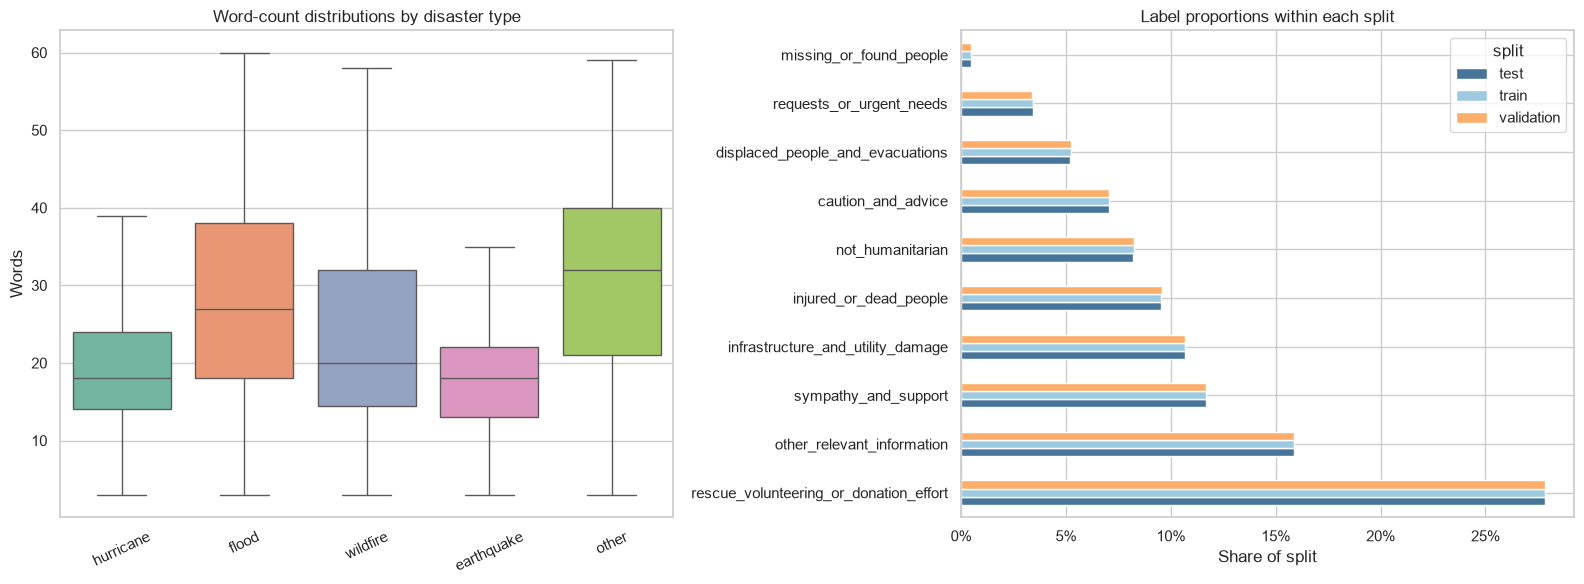

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_data = humaid_events.sample(min(len(humaid_events), 20000), random_state=36118)
sns.boxplot(data=plot_data, x="event_type", y="word_count", hue="event_type", showfliers=False, ax=axes[0], palette="Set2")
axes[0].set_title("Word-count distributions by disaster type")
axes[0].set_xlabel("")
axes[0].set_ylabel("Words")
axes[0].tick_params(axis="x", rotation=25)
if axes[0].legend_ is not None:
    axes[0].legend_.remove()

proportions = label_summary.pivot(index="class_label", columns="split", values="split_share").fillna(0)
proportions = proportions.loc[proportions.mean(axis=1).sort_values(ascending=False).index]
proportions.plot.barh(ax=axes[1], color=["#467599", "#9ecae1", "#fdae6b"])
axes[1].set_title("Label proportions within each split")
axes[1].set_xlabel("Share of split")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
fig.savefig(FIG_OUT / "humaid_text_length_and_split_proportions.png", dpi=180, bbox_inches="tight")
plt.show()

## Event-held-out evaluation plan

The official splits contain the same events in train, validation and test. They are useful for the main benchmark, but they do not show how a model works on a new disaster. The table below sets up a leave-one-event-out test.

In [9]:
event_holdout_rows = []
for event, group in humaid_events.groupby("event"):
    train_rows = int(((humaid_events["split"] == "train") & (humaid_events["event"] != event)).sum())
    heldout_dev = int(((humaid_events["split"] == "validation") & (humaid_events["event"] == event)).sum())
    heldout_test = int(((humaid_events["split"] == "test") & (humaid_events["event"] == event)).sum())
    label_support = group[group["split"] == "test"]["class_label"].value_counts()
    event_holdout_rows.append(
        {
            "event": event,
            "event_type": group["event_type"].iloc[0],
            "train_rows_excluding_event": train_rows,
            "heldout_validation_rows": heldout_dev,
            "heldout_test_rows": heldout_test,
            "test_labels_with_zero_support": int((label_support.reindex(humaid_events["class_label"].unique(), fill_value=0) == 0).sum()),
            "test_min_label_support": int(label_support.min()),
        }
    )
event_holdout_plan = pd.DataFrame(event_holdout_rows).sort_values("heldout_test_rows", ascending=False)
event_holdout_plan.to_csv(EDA_OUT / "humaid_event_holdout_plan.csv", index=False)
display(event_holdout_plan)

,event,event_type,train_rows_excluding_event,heldout_validation_rows,heldout_test_rows,test_labels_with_zero_support,test_min_label_support
8,hurricane_irma_2017,hurricane,46952,958,1862,1,25
7,hurricane_harvey_2017,hurricane,47153,929,1805,1,66
13,kerala_floods_2018,flood,47943,814,1582,1,11
5,hurricane_dorian_2019,hurricane,48202,776,1508,1,12
0,california_wildfires_2018,wildfire,48368,752,1461,0,16
9,hurricane_maria_2017,hurricane,48437,742,1442,1,26
6,hurricane_florence_2018,hurricane,49147,639,1241,1,11
2,cyclone_idai_2019,other,50778,401,779,0,4
1,canada_wildfires_2016,wildfire,51962,228,445,2,4
12,kaikoura_earthquake_2016,earthquake,51995,224,435,1,5


## CrisisMMD annotation EDA

CrisisMMD has three tasks. Informative and humanitarian labels use text and images. Damage severity mainly uses images. We keep the tasks separate because their labels are different.

In [10]:
CRISISMMD_DIR = CRISISMMD_RAW / "annotations" / "crisismmd_datasplit_all"
crisis_frames = []
for path in sorted(CRISISMMD_DIR.glob("*.tsv")):
    if path.name.startswith("task_"):
        parts = path.stem.split("_")
        task = "_".join(parts[1:-3]) if parts[-3:] == ["text", "img", path.stem.split("_")[-1]] else None
        if path.name.startswith("task_informative"):
            task = "informative"
        elif path.name.startswith("task_humanitarian"):
            task = "humanitarian"
        elif path.name.startswith("task_damage"):
            task = "damage_severity"
        split = "train" if path.name.endswith("_train.tsv") else "validation" if path.name.endswith("_dev.tsv") else "test"
        frame = pd.read_csv(path, sep="\t", encoding="utf-8")
        frame["task"] = task
        frame["split"] = split
        frame["text"] = frame["tweet_text"].fillna("").astype(str)
        crisis_frames.append(frame)
crisismmd = pd.concat(crisis_frames, ignore_index=True)
crisismmd["word_count"] = crisismmd["text"].str.findall(r"\b\w+\b").str.len()
crisismmd["char_count"] = crisismmd["text"].str.len()
crisismmd["normalised_text"] = crisismmd["text"].map(normalise_for_duplicate)

crisis_task_summary = crisismmd.groupby(["task", "split"]).size().rename("rows").reset_index()
crisis_label_distribution = crisismmd.groupby(["task", "split", "label"]).size().rename("rows").reset_index()
crisis_label_distribution["split_share"] = crisis_label_distribution["rows"] / crisis_label_distribution.groupby(["task", "split"])["rows"].transform("sum")
crisis_event_distribution = crisismmd.groupby(["task", "split", "event_name"]).size().rename("rows").reset_index()
crisis_text_stats = crisismmd.groupby(["task", "split", "label"]).agg(
    rows=("text", "size"),
    words_median=("word_count", "median"),
    words_p90=("word_count", lambda x: x.quantile(0.90)),
    chars_median=("char_count", "median"),
).reset_index()
crisis_duplicate_summary = crisismmd.groupby(["task", "split"]).agg(
    rows=("text", "size"),
    exact_duplicate_rows=("text", lambda x: int(x.duplicated(keep=False).sum())),
    normalised_duplicate_rows=("normalised_text", lambda x: int(x.duplicated(keep=False).sum())),
    unique_tweet_ids=("tweet_id", "nunique"),
    unique_image_ids=("image_id", "nunique"),
).reset_index()

agreement_frames = []
for task in ["informative", "humanitarian"]:
    subset = crisismmd[crisismmd["task"] == task].copy()
    for left, right in [("label_text", "label_image"), ("label", "label_text"), ("label", "label_image")]:
        if left in subset and right in subset:
            agreement_frames.append(
                pd.DataFrame(
                    {
                        "task": [task],
                        "comparison": [f"{left} vs {right}"],
                        "rows": [len(subset)],
                        "agreement_rate": [(subset[left].fillna("") == subset[right].fillna("")).mean()],
                    }
                )
            )
crisis_agreement = pd.concat(agreement_frames, ignore_index=True)

for frame, filename in [
    (crisis_task_summary, "crisismmd_task_summary.csv"),
    (crisis_label_distribution, "crisismmd_label_distribution.csv"),
    (crisis_event_distribution, "crisismmd_event_distribution.csv"),
    (crisis_text_stats, "crisismmd_text_statistics.csv"),
    (crisis_duplicate_summary, "crisismmd_duplicate_summary.csv"),
    (crisis_agreement, "crisismmd_annotation_agreement.csv"),
]:
    frame.to_csv(EDA_OUT / filename, index=False)

display(crisis_task_summary)
display(crisis_label_distribution.sort_values(["task", "split", "rows"], ascending=[True, True, False]))
display(crisis_agreement)

,task,split,rows
0,damage_severity,test,529
1,damage_severity,train,2468
2,damage_severity,validation,529
3,humanitarian,test,2237
4,humanitarian,train,13608
5,humanitarian,validation,2237
6,informative,test,2237
7,informative,train,13608
8,informative,validation,2237


,task,split,label,rows,split_share
2,damage_severity,test,severe_damage,332,0.627599
1,damage_severity,test,mild_damage,126,0.238185
0,damage_severity,test,little_or_no_damage,71,0.134216
5,damage_severity,train,severe_damage,1548,0.627229
4,damage_severity,train,mild_damage,587,0.237844
3,damage_severity,train,little_or_no_damage,333,0.134927
8,damage_severity,validation,severe_damage,332,0.627599
7,damage_severity,validation,mild_damage,126,0.238185
6,damage_severity,validation,little_or_no_damage,71,0.134216
13,humanitarian,test,not_humanitarian,849,0.379526


,task,comparison,rows,agreement_rate
0,informative,label_text vs label_image,18082,0.702798
1,informative,label vs label_text,18082,0.849961
2,informative,label vs label_image,18082,0.852837
3,humanitarian,label_text vs label_image,18082,0.446798
4,humanitarian,label vs label_text,18082,0.721823
5,humanitarian,label vs label_image,18082,0.724975


## CrisisMMD label and agreement figures

These plots show why CrisisMMD is a useful second benchmark but should not be merged with HumAID. Its humanitarian labels are uneven, and text and image labels do not always agree.

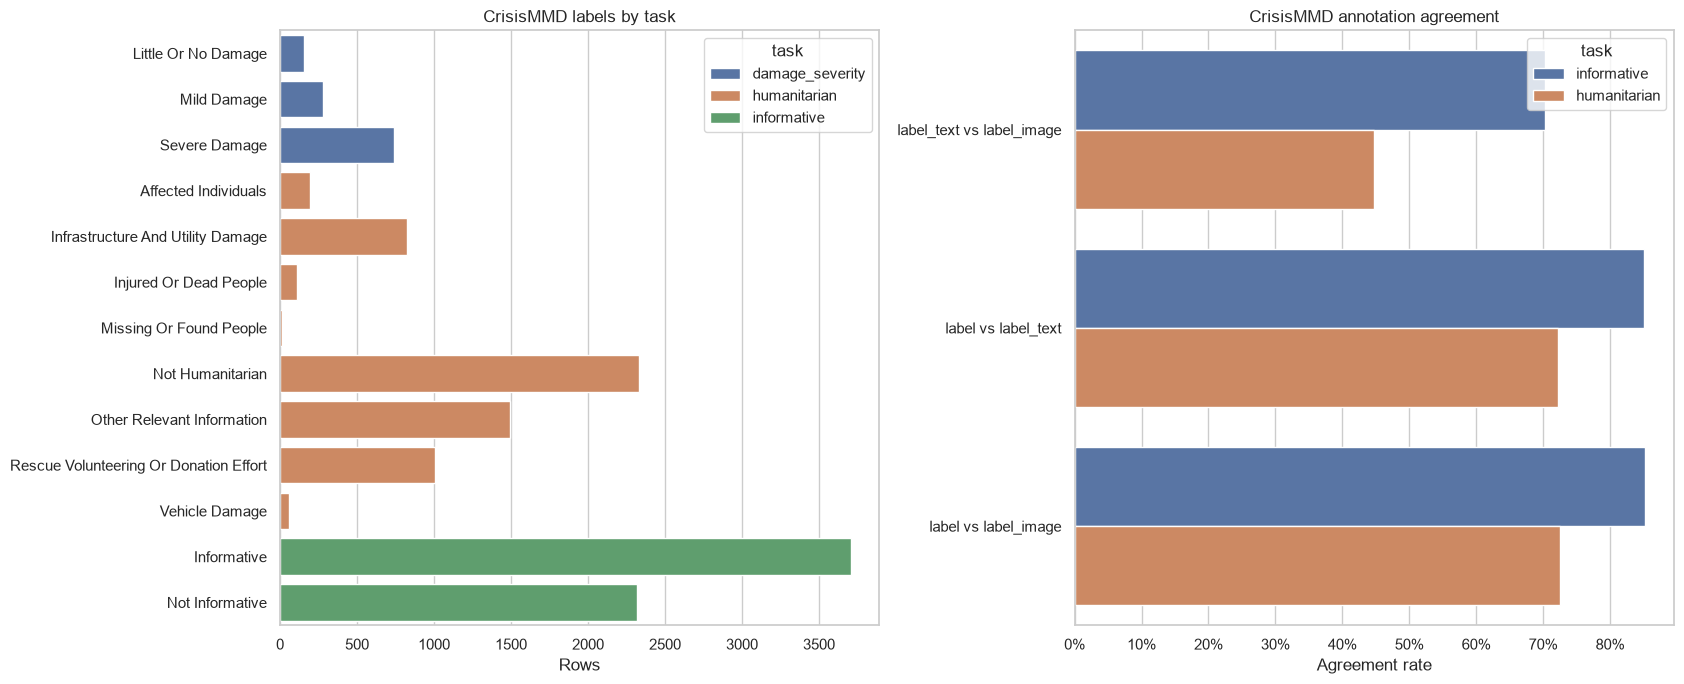

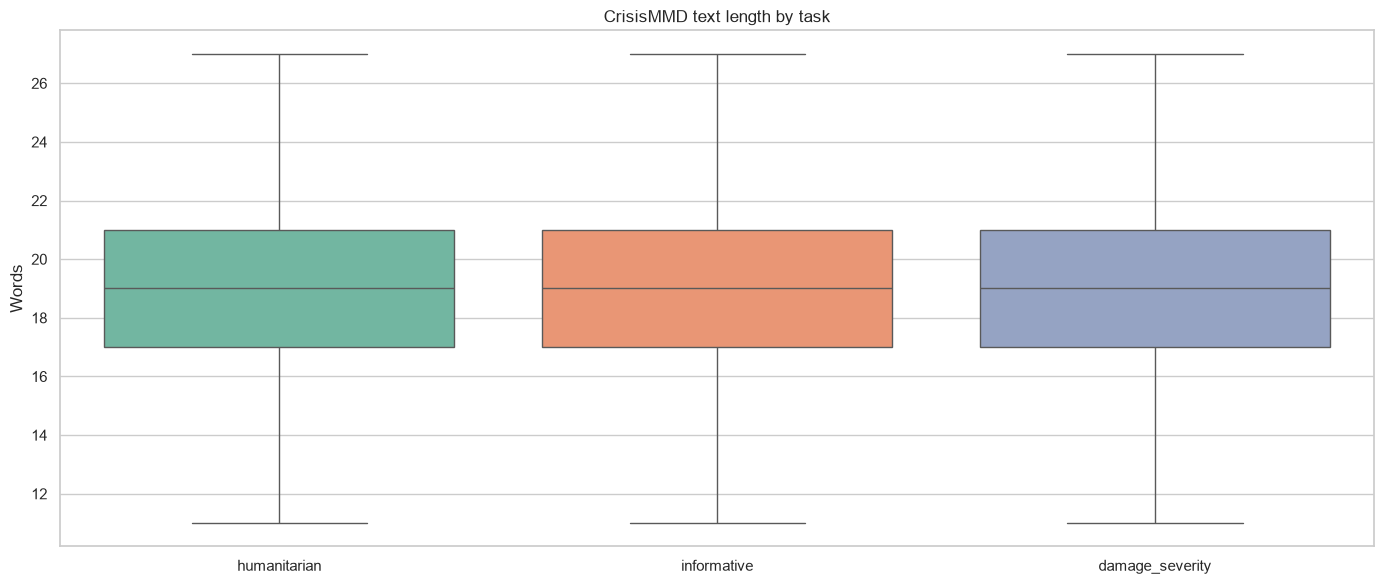

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
crisis_plot = crisis_label_distribution.copy()
crisis_plot["label_short"] = crisis_plot["label"].str.replace("_", " ").str.title()
sns.barplot(data=crisis_plot, x="rows", y="label_short", hue="task", errorbar=None, ax=axes[0])
axes[0].set_title("CrisisMMD labels by task")
axes[0].set_xlabel("Rows")
axes[0].set_ylabel("")

if len(crisis_agreement):
    sns.barplot(data=crisis_agreement, x="agreement_rate", y="comparison", hue="task", errorbar=None, ax=axes[1])
    axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    axes[1].set_title("CrisisMMD annotation agreement")
    axes[1].set_xlabel("Agreement rate")
    axes[1].set_ylabel("")
plt.tight_layout()
fig.savefig(FIG_OUT / "crisismmd_labels_and_agreement.png", dpi=180, bbox_inches="tight")
plt.show()

plt.figure(figsize=(14, 6))
sns.boxplot(data=crisismmd.sample(min(len(crisismmd), 16000), random_state=36118), x="task", y="word_count", hue="task", showfliers=False, palette="Set2")
plt.title("CrisisMMD text length by task")
plt.xlabel("")
plt.ylabel("Words")
plt.tight_layout()
plt.savefig(FIG_OUT / "crisismmd_text_length.png", dpi=180, bbox_inches="tight")
plt.show()

## Compact findings for the team

This final cell saves a summary for the team. It records the main data facts and the next steps, so other members can start without running the whole EDA first.

In [12]:
top_humaid_labels = label_summary.groupby("class_label", as_index=False)["rows"].sum().sort_values("rows", ascending=False)
top_crisis_humanitarian = crisis_label_distribution[crisis_label_distribution["task"] == "humanitarian"].groupby("label", as_index=False)["rows"].sum().sort_values("rows", ascending=False)
summary = {
    "humaid": {
        "rows": int(len(humaid_events)),
        "splits": {row["split"]: int(row["rows"]) for _, row in split_summary.iterrows()},
        "events": int(humaid_events["event"].nunique()),
        "event_types": sorted(humaid_events["event_type"].unique().tolist()),
        "labels_in_downloaded_files": sorted(humaid_events["class_label"].unique().tolist()),
        "exact_duplicate_rows": exact_duplicate_count,
        "normalised_duplicate_rows": normalised_duplicate_count,
        "cross_split_normalised_duplicate_groups": cross_split_duplicate_groups,
        "recommended_primary_task": "HumAID text-only humanitarian classification",
        "recommended_generalisation_test": "leave-one-disaster-event-out evaluation",
    },
    "crisismmd": {
        "task_rows": {f"{row['task']}__{row['split']}": int(row["rows"]) for _, row in crisis_task_summary.iterrows()},
        "tasks": sorted(crisismmd["task"].unique().tolist()),
        "humanitarian_labels": sorted(crisismmd.loc[crisismmd["task"] == "humanitarian", "label"].unique().tolist()),
        "image_archive_downloaded": False,
    },
}
(EDA_OUT / "eda_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "humaid": {
    "rows": 76484,
    "splits": {
      "test": 15160,
      "train": 53531,
      "validation": 7793
    },
    "events": 19,
    "event_types": [
      "earthquake",
      "flood",
      "hurricane",
      "other",
      "wildfire"
    ],
    "labels_in_downloaded_files": [
      "caution_and_advice",
      "displaced_people_and_evacuations",
      "infrastructure_and_utility_damage",
      "injured_or_dead_people",
      "missing_or_found_people",
      "not_humanitarian",
      "other_relevant_information",
      "requests_or_urgent_needs",
      "rescue_volunteering_or_donation_effort",
      "sympathy_and_support"
    ],
    "exact_duplicate_rows": 12,
    "normalised_duplicate_rows": 12,
    "cross_split_normalised_duplicate_groups": 4,
    "recommended_primary_task": "HumAID text-only humanitarian classification",
    "recommended_generalisation_test": "leave-one-disaster-event-out evaluation"
  },
  "crisismmd": {
    "task_rows": {
      "damage_severity__tes